# 2. Datan ymmärtäminen

## 2.1 Backend alustus

Alustetaan backend hyödyntämään tehokkainta reittiä mallin kehittämiseen

In [1]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import platform
import pandas as pd

os.environ["KERAS_BACKEND"] = "tensorflow"

import tensorflow as tf

# Apple Silicon Macilla TensorFlow käyttää CPU:ta nopeempaa ja tarkempaa mallia varten
if platform.system() == "Darwin" and platform.machine() == "arm64":
    tf.config.set_visible_devices([], "GPU")

## 2.2 Datan haku ja tulkinta

Haetaan data kerasin avulla ja tarkistellaan sen kokoa ja tyyppejä

In [3]:
import keras
from keras import layers
import numpy as np

# Datan haku ja tulkinta
keras.utils.set_random_seed(0)
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
print(f"x_train: {x_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"x_test: {x_test.shape}")
print(f"y_test: {y_test.shape}")
print(f"Minimi: {x_train.min()}")
print(f"Maksimi: {x_train.max()}")
print(f"Tietotyyppi: {x_train.dtype}")
print(f"Luokat: {np.unique(y_train)}")

# Tyhjät arvot
print("\nTarkistetaan tyhjät arvot:\n")
print("\nTreenidata:\n")
print(f"Treeni kuvien tyhjien arvojen summa: {np.isnan(x_train).sum()}")
print(f"Treeni kuvien kohteiden tyhjien arvojen summa: {np.isnan(y_train).sum()}")
print("\nTestidata\n")
print(f"Testi kuvien tyhjien arvojen summa: {np.isnan(x_test).sum()}")
print(f"Testi kuvien kohteiden tyhjien arvojen summa: {np.isnan(y_test).sum()}")

x_train: (50000, 32, 32, 3)
y_train: (50000, 1)
x_test: (10000, 32, 32, 3)
y_test: (10000, 1)
Minimi: 0
Maksimi: 255
Tietotyyppi: uint8
Luokat: [0 1 2 3 4 5 6 7 8 9]

Tarkistetaan tyhjät arvot:


Treenidata:

Treeni kuvien tyhjien arvojen summa: 0
Treeni kuvien kohteiden tyhjien arvojen summa: 0

Testidata

Testi kuvien tyhjien arvojen summa: 0
Testi kuvien kohteiden tyhjien arvojen summa: 0


## 2.3 Datan tulkinta
CIFAR-10 antaa 60000 kuvaa, joista 50000 menee koulutukseen ja 10000 testaamiseen. Kuvat on koossa 32 x 32 ja 3 värikanavaa. Värit on 0-255 eli 8 bittisiä. Kuvat on jaettu 10 eri luokkaan: 0 = lentokone, 1 = auto, 2 = lintu, 3 = kissa, 4 = peura, 5 = koira, 6 = sammakko, 7 = hevonen, 8 = laiva ja 9 = kuorma-auto [lähde dokumentaatio](https://keras.io/api/datasets/cifar10/?utm_source=chatgpt.com).

Tyhjiä arvoja ei ole datassa.

In [4]:
# Ensimmäiset 10 luokkatunnusta
print("Datan ensimmäisen kymmenen rivin luokkatunnukset:\n")
print(y_train[:10])

# Ensimmäisen kuvan kaikki pikseliarvot
print("\nEnsimmäisen kuvan kaikki pikseliarvot:\n")
print(x_train[0])

# Ensimmäisen kuvan koko ja muoto
print("\nEnsimmäisen kuvan koko 32 x 32 =\n")
print(x_train[0].size)
print("\nEnsimmäisen kuvan muoto\n")
print(x_train[0].shape)

# Ensimmäisen pikselin RGB-arvot
print("\nEsimmäisen pikselin RGB arvot:\n")
print(x_train[0, 0, 0])

Datan ensimmäisen kymmenen rivin luokkatunnukset:

[[6]
 [9]
 [9]
 [4]
 [1]
 [1]
 [2]
 [7]
 [8]
 [3]]

Ensimmäisen kuvan kaikki pikseliarvot:

[[[ 59  62  63]
  [ 43  46  45]
  [ 50  48  43]
  ...
  [158 132 108]
  [152 125 102]
  [148 124 103]]

 [[ 16  20  20]
  [  0   0   0]
  [ 18   8   0]
  ...
  [123  88  55]
  [119  83  50]
  [122  87  57]]

 [[ 25  24  21]
  [ 16   7   0]
  [ 49  27   8]
  ...
  [118  84  50]
  [120  84  50]
  [109  73  42]]

 ...

 [[208 170  96]
  [201 153  34]
  [198 161  26]
  ...
  [160 133  70]
  [ 56  31   7]
  [ 53  34  20]]

 [[180 139  96]
  [173 123  42]
  [186 144  30]
  ...
  [184 148  94]
  [ 97  62  34]
  [ 83  53  34]]

 [[177 144 116]
  [168 129  94]
  [179 142  87]
  ...
  [216 184 140]
  [151 118  84]
  [123  92  72]]]

Ensimmäisen kuvan koko 32 x 32 =

3072

Ensimmäisen kuvan muoto

(32, 32, 3)

Esimmäisen pikselin RGB arvot:

[59 62 63]


## 2.4 Kuvien ja datan tulkinta

Kuvat ovat jo oikeassa muodossa (32 x 32 x 3), värikuvia (pikselit välillä 0-255) ja 3 kanavisia. Tyhjiä arvoja ei ole.

# 3. Datan valmistelu

## 3.1 Nimetään luokat

Määritetään luokkien nimet visualisoinnin helpottamiseski:

In [5]:
# Määritetään luokkien nimet
class_names = [
    "lentokone",
    "auto",
    "lintu",
    "kissa",
    "peura",
    "koira",
    "sammakko",
    "hevonen",
    "laiva",
    "kuorma-auto"
]

## 3.2 Normalisoidaan pikselit

Alustetaan pikselit arvojen 0-1 välille jakamalla koolla 255. Näin neuroverkko oppii paremmin datan piirteet, kun syötearvot ovat pienellä ja yhtenäisellä asteikolla.

In [6]:
# Normalisoidaan pikseliarvot välille 0–1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

In [7]:
# Datan tarkistus
print(f"Treeni kuvien muoto {x_train.shape}")
print(f"Treeni kuvien luokkien muoto {y_train.shape}")

print(f"Testi kuvien muoto {x_test.shape}")
print(f"Testi kuvien luokkien muoto {y_test.shape}")

# Tarkistetaan normalisoinnin onnistuminen
print(f"Minimi treenidatassa: {x_train.min()}")
print(f"Maksimi treenidatassa: {x_train.max()}")
print(f"Kesiarvo treenidatassa: {x_train.mean()}")

print(f"Minimi testidatassa: {x_test.min()}")
print(f"Maksimi testidatassa: {x_test.max()}")
print(f"Kesiarvo testidatassa: {x_test.mean()}")

Treeni kuvien muoto (50000, 32, 32, 3)
Treeni kuvien luokkien muoto (50000, 1)
Testi kuvien muoto (10000, 32, 32, 3)
Testi kuvien luokkien muoto (10000, 1)
Minimi treenidatassa: 0.0
Maksimi treenidatassa: 1.0
Kesiarvo treenidatassa: 0.4733648896217346
Minimi testidatassa: 0.0
Maksimi testidatassa: 1.0
Kesiarvo testidatassa: 0.4765852391719818


## 3.3 Datan valmistelun johtopäätökset
Pikselit normalisoitiin 0-1 välille ja muoto säilyi ennallaan

# 4. Mallinnus

Luodaan erilaisia malleja saadakseen mahdollisimman tehokas ja tarkka ennustamiseen uuden kuvan mukaan luokittelemaan oikein.

Luodaan ajastusfunktio (AI-generoitu) tallentaakseen ajat selkeästi historiaan.

Lisäksi määritetään yleinen pysäytin.

In [8]:
# AI:lla generoitu timeri saadakseen ajat selkeämmin ajat näkyviin aikavertailuun
import time

class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.perf_counter() - self.start_time
        self.epoch_times.append(elapsed)


In [9]:
# Määritetään omat ajastimet selkeyttämiseksi
timer_32_64_2layer = EpochTimer()
timer_64_128_2layer = EpochTimer()

## 4.1 Pysäyttimen määritys

Määritetään stop arvo jotta ei tarvitse kaikkia kierroksia (epochs) käydä, vaan pysäytetään kun malli alkaa ylioppia. Seurataan 3 peräkkäistä validaatio menetyksen (validation loss) -arvoa.

In [10]:
# Määritetään yleinen pysäytin
stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                     restore_best_weights=True)

### 4.2 CNN-malli: 32 ja 64 suodatinta
Kokeillaan miten malli kehittyy kaksikerroksisella mallilla, jossa ensimmäinen kerros käyttää 32 suodattinta, antaen 32 piirrekarttaa ja toinen kerrot 64 suodatinta ja 64 eri piirrekarttaa. Kernel koolla 3 ja sisennys arvolla "same". Aktivointi on ReLU ja askelpituutena (stride) oletusarvo 1.

#### 4.2.1 Mallin rakentaminen

In [11]:
model32_64_2layer = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"), # Ensimmäinen kerros 32 suodatinta
    layers.MaxPooling2D(pool_size=2),  # Puolitetaan piirrekarttojen korkeus ja leveys 16 x 16 x 32
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"), # Toinen kerros 64 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 8 x 8 x 64
    layers.Flatten(),
    layers.Dense(10, activation="softmax")  # valitaan 10 luokan takia
])

#### 4.2.2 Mallin koulutusasetusten määrittäminen (compile)

Optimoijaksi valitaan adam, koska se muokkaa painokertoimien päivityksiä koulutuksen aikana ja pyrkii pienentämää loss-arvoa. Kokonaisluku luokituksen vuoksi (0-9) sparse_categorical_crossentropy parametri toimii parhaiten. Arviointi metriikka on tarkkuus (accuracy). Pysäytetään kun validoinnin menetys (validation loss) nousee 3 peräkkäisen arvon jälkeen.

In [12]:
model32_64_2layer.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

#### 4.2.3 Mallin kouluttaminen

In [13]:
# Tallennetaan historia myöhempää tarkastelua varten.
history_32_64_2layer = model32_64_2layer.fit(x_train, y_train, epochs=20, validation_split=0.1, callbacks=[stop, timer_32_64_2layer])

# Tallennetaan ajat historiaan myöhempää tarkastelua varten.
history_32_64_2layer.history["epoch_time_seconds"] = timer_32_64_2layer.epoch_times

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.4946 - loss: 1.4254 - val_accuracy: 0.6090 - val_loss: 1.1326
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.6264 - loss: 1.0731 - val_accuracy: 0.6564 - val_loss: 1.0053
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.6732 - loss: 0.9445 - val_accuracy: 0.6680 - val_loss: 0.9721
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7039 - loss: 0.8596 - val_accuracy: 0.6906 - val_loss: 0.9184
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.7298 - loss: 0.7900 - val_accuracy: 0.6954 - val_loss: 0.8987
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7505 - loss: 0.7310 - val_accuracy: 0.7080 - val_loss: 0.8798
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7672 - loss: 0.6808 - val_accuracy: 0.7052 - val_loss: 0.9011
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7832 - loss: 0.6360 - 

#### 4.2.4 Mallin arviointi

Arvioidaan malli sen menetyksen (test loss) ja tarkkuuden (test accuracy) mukaan.

In [14]:
test_loss_32_64_2layer, test_accuracy_32_64_2layer = model32_64_2layer.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Testin menetys (loss): {test_loss_32_64_2layer:.4f}")
print(f"Testin tarkkuus (accuracy): {test_accuracy_32_64_2layer:.2%}")

Testin menetys (loss): 0.9040
Testin tarkkuus (accuracy): 69.60%


#### 4.2.5 Tulosten visualisointi ja analysointi
Taulukoidaan mallin validointi menetys (validation loss) ja menetys (loss), ja mallin suoritusajat

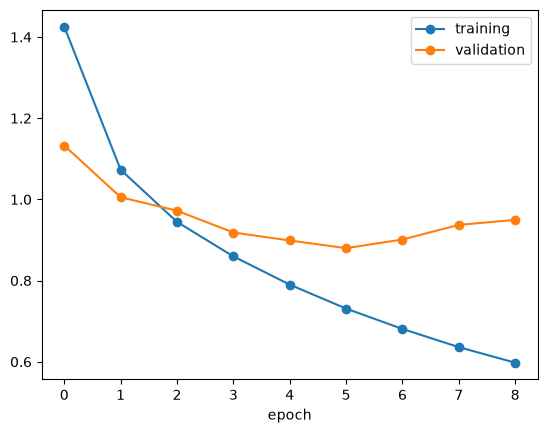

Epoch,Aika (s)
1,8.83
2,8.45
3,8.60
4,9.12
5,8.40
6,8.77
Keski suoritusaika,8.70
Kokonaissuoritusaika,52.18


In [15]:
import matplotlib.pyplot as plt

plt.plot(history_32_64_2layer.history["loss"], marker="o", label="training")
plt.plot(history_32_64_2layer.history["val_loss"], marker="o", label="validation")
plt.xlabel("epoch")
plt.legend()
plt.show()

# Epochien suoritusajat dataframeen huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_32_64_2layer = pd.DataFrame({"Epoch": range(1, len(timer_32_64_2layer.epoch_times[:-3]) + 1), "Aika (s)": timer_32_64_2layer.epoch_times[:-3]})

# Keskimääräinen suoritusaika huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_32_64_2layer.loc[len(df_times_32_64_2layer)] = ["Keski suoritusaika", sum(timer_32_64_2layer.epoch_times[:-3]) / len(timer_32_64_2layer.epoch_times[:-3])]

# Kokonaissuoritusaika huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_32_64_2layer.loc[len(df_times_32_64_2layer)] = ["Kokonaissuoritusaika", sum(timer_32_64_2layer.epoch_times[:-3])]

# Pyöristetään ajat 2 tarkkuudella ja näytetään aikojen dataframe. Poistetaan turha indeksi visualisoinnin selkeyttämiseksi.
display(df_times_32_64_2layer.style.hide(axis="index").format({"Aika (s)": "{:.2f}"}))

#### 4.2.6 Johtopäätökset

Pysähdys tapahtui 8 epochin jälkeen, se ja kuvaaja indikoi epochille arvoa 5. Malli suoriutui heikolla tarkkuudella (69%), aika oli **TARKISTA TÄMÄ VIELÄ!** "nopeahko" (n. 52s). Loss arvolla 0.9 ei ole myöskään speksien mukainen.

### 4.3 CNN-malli: 64 ja 128 suodatinta
Kokeillaan miten malli kehittyy kaksikerroksisella mallilla, jossa ensimmäinen kerros käyttää 64 suodattinta, antaen 64 piirrekarttaa ja toinen kerrot 128 suodatinta ja 128 eri piirrekarttaa. Kernel koolla 3 ja sisennys arvolla "same". Aktivointi on ReLU ja askelpituutena (stride) oletusarvo 1.

#### 4.3.1 Mallin rakentaminen

In [16]:
model64_128_2layer = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"), # Ensimmäinen kerros 64 suodatinta
    layers.MaxPooling2D(pool_size=2),  # Puolitetaan piirrekarttojen korkeus ja leveys 16 x 16 x 64
    layers.Conv2D(128, kernel_size=3, padding="same", activation="relu"), # Toinen kerros 128 suodatinta
    layers.MaxPooling2D(pool_size=2), # Puolitetaan piirrekarttojen korkeus ja leveys 8 x 8 x 128
    layers.Flatten(),
    layers.Dense(10, activation="softmax")  # valitaan 10 luokan takia
])

#### 4.3.2 Mallin koulutusasetusten määrittäminen (compile)

Optimoijaksi valitaan adam, koska se muokkaa painokertoimien päivityksiä koulutuksen aikana ja pyrkii pienentämää loss-arvoa. Kokonaisluku luokituksen vuoksi (0-9) sparse_categorical_crossentropy parametri toimii parhaiten. Arviointi metriikka on tarkkuus (accuracy). Pysäytetään samaan tapaan kuin muissa.

In [17]:
model64_128_2layer.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

#### 4.3.3 Mallin kouluttaminen

In [18]:
# Tallennetaan historia myöhempää tarkastelua varten.
history_64_128_2layer = model64_128_2layer.fit(x_train, y_train, epochs=20, validation_split=0.1, callbacks=[stop, timer_64_128_2layer])

# Tallennetaan ajat historiaan myöhempää tarkastelua varten.
history_64_128_2layer.history["epoch_time_seconds"] = timer_64_128_2layer.epoch_times

Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - accuracy: 0.5184 - loss: 1.3615 - val_accuracy: 0.6350 - val_loss: 1.0500
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - accuracy: 0.6620 - loss: 0.9831 - val_accuracy: 0.6826 - val_loss: 0.9260
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - accuracy: 0.7113 - loss: 0.8406 - val_accuracy: 0.7054 - val_loss: 0.8730
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 22s 16ms/step - accuracy: 0.7466 - loss: 0.7400 - val_accuracy: 0.7170 - val_loss: 0.8684
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 23s 16ms/step - accuracy: 0.7756 - loss: 0.6567 - val_accuracy: 0.7142 - val_loss: 0.8760
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 24s 17ms/step - accuracy: 0.7991 - loss: 0.5849 - val_accuracy: 0.7110 - val_loss: 0.9136
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 25s 18ms/step - accuracy: 0.8241 - loss: 0.5203 - val_accuracy: 0.7160 - val_loss: 0.9398


#### 4.3.4 Mallin arviointi

Arvioidaan malli sen menetyksen (test loss) ja tarkkuuden (test accuracy) mukaan.

In [19]:
test_loss_64_128_2layer, test_accuracy_64_128_2layer = model64_128_2layer.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Testin menetys (loss): {test_loss_64_128_2layer:.4f}")
print(f"Testin tarkkuus (accuracy): {test_accuracy_64_128_2layer:.2%}")

Testin menetys (loss): 0.8956
Testin tarkkuus (accuracy): 70.18%


#### 4.3.5 Tulosten visualisointi ja analysointi
Taulukoidaan mallin validointi menetys (validation loss) ja menetys (loss), ja mallin suoritusajat

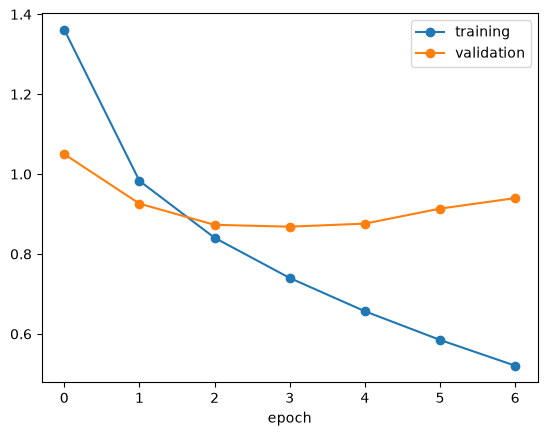

Epoch,Aika (s)
1,21.52
2,21.31
3,21.72
4,21.98
Keski suoritusaika,21.63
Kokonaissuoritusaika,86.54


In [20]:
plt.plot(history_64_128_2layer.history["loss"], marker="o", label="training")
plt.plot(history_64_128_2layer.history["val_loss"], marker="o", label="validation")
plt.xlabel("epoch")
plt.legend()
plt.show()

# Epochien suoritusajat dataframeen huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_64_128_2layer = pd.DataFrame({"Epoch": range(1, len(timer_64_128_2layer.epoch_times[:-3]) + 1), "Aika (s)": timer_64_128_2layer.epoch_times[:-3]})

# Keskimääräinen suoritusaika huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_64_128_2layer.loc[len(df_times_64_128_2layer)] = ["Keski suoritusaika", sum(timer_64_128_2layer.epoch_times[:-3]) / len(timer_64_128_2layer.epoch_times[:-3])]

# Kokonaissuoritusaika huomioiden pysäyttäjä (poistetaan viimeiset 3 epochin suoritusaikaa).
df_times_64_128_2layer.loc[len(df_times_64_128_2layer)] = ["Kokonaissuoritusaika", sum(timer_64_128_2layer.epoch_times[:-3])]

# Pyöristetään ajat 2 tarkkuudella ja näytetään aikojen dataframe. Poistetaan turha indeksi visualisoinnin selkeyttämiseksi.
display(df_times_64_128_2layer.style.hide(axis="index").format({"Aika (s)": "{:.2f}"}))

#### 4.3.6